>>> 1. 获取主力连续合约日线 ...
成功获取品种数: 60 用时 1.7s
通过数据完整性/流动性过滤的品种数 N = 59
交易日数 D = 882 特征数 F = 15 数据区间: 2023-05-04 ~ 2026-12-18


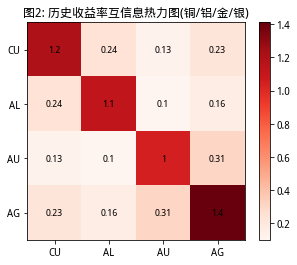

图2 互信息矩阵:
       CU     AL     AU     AG
CU  1.203  0.240  0.125  0.225
AL  0.240  1.129  0.100  0.158
AU  0.125  0.100  1.047  0.310
AG  0.225  0.158  0.310  1.411


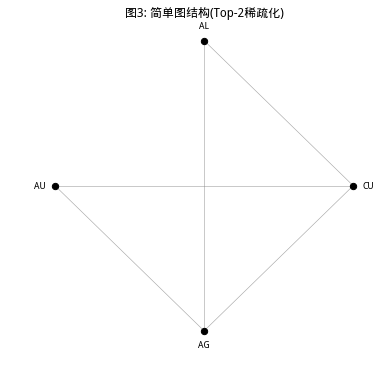

>>> 2. 构造样本与动态图 ...
样本数 train/val/test = 278 / 81 / 358
训练集: 2024-01-02~2025-02-28 | 验证集: 2025-03-03~2025-06-30 | 测试集: 2025-07-01~2026-12-17


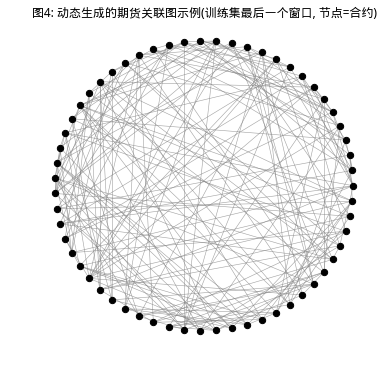

>>> 3. 训练扩散图神经网络 (device=cpu) ...
epoch   1 | train loss 0.7129 acc 0.5084 | val loss 0.6956 acc 0.5275
epoch   5 | train loss 0.6881 acc 0.5383 | val loss 0.6966 acc 0.4871
epoch  10 | train loss 0.6734 acc 0.5872 | val loss 0.7094 acc 0.4681
早停于 epoch 12
GGD各阶权重 alpha_k = [0.339 0.332 0.33]
验证集方向准确率 0.4702 | 测试集方向准确率 0.5175

表1: 扩散图神经网络策略指标
                        年化收益率   年化波动率  Sortino比率    最大回撤    夏普比率    信息比率
2025-07-02~2026-12-18  0.1503  0.1191     2.0754 -0.1024  1.2621  0.1936

与传统截面策略对比:
          年化收益率   年化波动率  Sortino比率    最大回撤    夏普比率    信息比率
扩散图神经网络  0.1503  0.1191     2.0754 -0.1024  1.2621  0.1936
短周期动量    0.1489  0.1795     1.2386 -0.1395  0.8292  0.1830
长周期动量   -0.0030  0.1972    -0.0213 -0.2468 -0.0153 -0.5706
偏度      -0.0201  0.0865    -0.3183 -0.1453 -0.2330 -0.9078
期限结构    -0.2014  0.1508    -1.7774 -0.2700 -1.3357 -2.0887


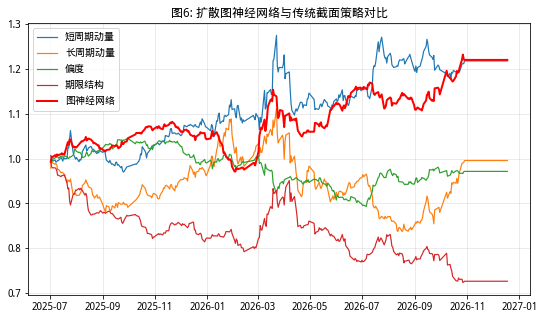

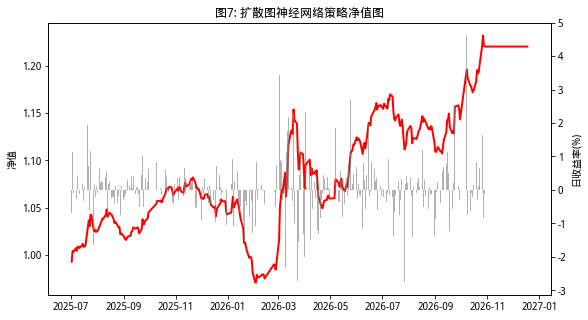


月度收益率(%):
2025-07-31     2.58
2025-08-31    -0.27
2025-09-30     2.16
2025-10-31     2.07
2025-11-30     0.24
2025-12-31    -2.46
2026-01-31    -5.86
2026-02-28     1.04
2026-03-31    10.07
2026-04-30    -2.97
2026-05-31     5.37
2026-06-30     3.55
2026-07-31    -2.08
2026-08-31    -1.15
2026-09-30     2.15
2026-10-31     6.73
2026-11-30     0.00
2026-12-31     0.00
Freq: M


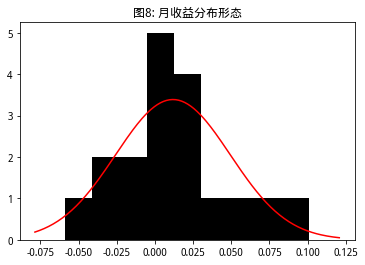

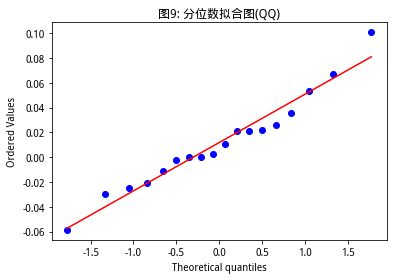

月收益偏度 0.509 | 峰度(超额) 0.335

完成。总用时 69.9s


In [1]:
# -*- coding: utf-8 -*-
"""
复现：华泰期货《深度学习模型系列(一) 基于扩散图神经网络的CTA策略初探》
运行环境：聚宽研究环境  (Python 3.6.7 / numpy 1.19.5 / pandas 0.23.4 / scipy 1.2.0 / torch 1.0.0)
说明：
  * 数据全部用 get_price 直接取到内存使用，不写任何文件；结果全部 print / plt.show() 显示。
  * torch 1.0.0 没有 nn.MultiheadAttention，多头注意力为手写实现。
  * 模块：互信息(直方图,10箱)动态建图 -> Top-k稀疏+对称归一化 -> 拉普拉斯位置编码
          -> 线性嵌入 -> 广义图扩散(GGD, 可学习衰减权重) -> 多头注意力 -> MLP(Softmax二分类)
          -> 联合损失 CE + lambda*R_G -> 日频Top-5多/Bottom-5空回测
"""
import copy
import math
import time
import warnings
import numpy as np
import pandas as pd
from scipy import stats
import torch
import torch.nn as nn
import torch.nn.functional as Fn
import matplotlib.pyplot as plt

try:
    from jqdata import *   # 聚宽研究环境中 get_price 已内置，这里只是保险
except Exception:
    pass

warnings.filterwarnings('ignore')
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# ============================== 参数区 ==============================
START = '2024-01-01'          # 样本起点
END = '2026-12-20'            # 样本终点(超过数据库最新日期时自动截断)
DATA_START = '2023-05-01'     # 仅用于滚动特征预热(样本本身从START开始)

# 数据划分(研报: 训练2年/验证1.5年/测试约1.9年；这里按 20240101-20261220 区间等比例划分，可自行修改)
TRAIN_END = '2025-02-28'
VAL_END = '2025-06-30'        # 之后为测试集

T_WIN = 21                    # 过去21个交易日作为输入窗口
TOPK = 5                      # 每个品种保留的最强信息连接边数
SIM_THRESH = 0.0              # 相似度阈值(与Top-k共同使用)
K_PE = 4                      # 拉普拉斯位置编码维度
D_MODEL = 16                  # 隐藏维度d
K_DIFF = 3                    # 图扩散阶数K
HEADS = 4                     # 注意力头数
HIDDEN = 64
DROP = 0.3
LAM = 0.1                     # 图结构正则系数lambda
LR = 1e-3
WD = 1e-3
BS = 16
EPOCHS = 60
PATIENCE = 10
SEED = 42

N_LONG = 5                    # 多头5只，空头5只
COST = 0.0                    # 单边换手成本(研报未计入，默认0，可设0.0003等)
RET_CLIP = 0.12              # 单日收益截断，抑制主力连续合约换月跳空
ZW = 60                       # 特征滚动标准化窗口
MIN_MED_VOL = 2000            # 品种流动性过滤(样本期日成交量中位数，手)

np.random.seed(SEED)
torch.manual_seed(SEED)
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ============================== 品种池(主力连续) ==============================
CODES = (
    [x + '9999.XDCE' for x in ['A', 'B', 'M', 'C', 'Y', 'L', 'P', 'V', 'J', 'JM', 'I', 'JD',
                              'PP', 'CS', 'EG', 'RR', 'EB', 'PG', 'LH']] +
    [x + '9999.XSGE' for x in ['AL', 'RU', 'FU', 'CU', 'ZN', 'AU', 'RB', 'PB', 'AG', 'BU', 'HC',
                              'SN', 'NI', 'SP', 'SS', 'AO', 'BR']] +
    [x + '9999.XINE' for x in ['SC', 'NR', 'LU', 'BC']] +
    [x + '9999.XZCE' for x in ['CF', 'SR', 'TA', 'OI', 'FG', 'RM', 'MA', 'SF', 'SM', 'CY', 'AP',
                              'CJ', 'UR', 'SA', 'PF', 'PK', 'SH', 'PX']] +
    [x + '9999.GFEX' for x in ['SI', 'LC']]
)

FIELDS = ['open', 'close', 'high', 'low', 'volume', 'money', 'avg', 'open_interest']


def fetch(code, fields):
    try:
        df = get_price(code, start_date=DATA_START, end_date=END, frequency='daily',
                       fields=fields, skip_paused=False)
        if df is None or len(df) == 0:
            return None
        df = df.dropna(subset=['close'])
        return df if len(df) > 0 else None
    except Exception as e:
        print('获取失败', code, str(e)[:60])
        return None


print('>>> 1. 获取主力连续合约日线 ...')
t0 = time.time()
raw = {}
for code in CODES:
    df = fetch(code, FIELDS)
    if df is not None:
        df = df.copy()
        df['avg'] = df['avg'].fillna(df['close'])
        raw[code] = df
print('成功获取品种数:', len(raw), '用时 %.1fs' % (time.time() - t0))

# ============================== 特征工程(共15个特征) ==============================


def build_features(df):
    c = df['close']
    pc = c.shift(1)
    ret1 = (c / pc - 1).clip(-RET_CLIP, RET_CLIP)
    f = pd.DataFrame(index=df.index)
    # 价格类(相对前收)
    f['open'] = df['open'] / pc - 1
    f['high'] = df['high'] / pc - 1
    f['low'] = df['low'] / pc - 1
    f['close'] = c / c.rolling(20).mean() - 1
    f['avg'] = df['avg'] / pc - 1
    # 量/额/持仓
    f['lvol'] = np.log1p(df['volume'])
    f['lmoney'] = np.log1p(df['money'])
    f['loi'] = np.log1p(df['open_interest'])
    # 技术面
    f['ret1'] = ret1
    f['ret5'] = c / c.shift(5) - 1
    f['vol5'] = ret1.rolling(5).std()
    f['range'] = (df['high'] - df['low']) / pc
    # 基本面(持仓/成交变化)
    f['dvol'] = np.log1p(df['volume']).diff()
    f['doi'] = np.log1p(df['open_interest']).diff()
    f['dmoney'] = np.log1p(df['money']).diff()
    # 标准化为同量纲：滚动z-score(仅用当日及以前信息)
    z = (f - f.rolling(ZW).mean()) / (f.rolling(ZW).std() + 1e-12)
    z = z.replace([np.inf, -np.inf], np.nan).clip(-5, 5)
    return z


# ============================== 对齐&过滤 ==============================
base = None
for code, df in raw.items():
    if base is None or len(df) > len(base):
        base = df.index
base = base.sort_values()
start_ts = pd.Timestamp(START)
n_sample_days = float(len(base[base >= start_ts]))

codes = []
for code, df in raw.items():
    ok_first = df.index[0] <= start_ts - pd.Timedelta(days=90)
    sub = df.loc[start_ts:]
    cov = len(sub) / max(n_sample_days, 1.0)
    ok_vol = (len(sub) > 0) and (sub['volume'].median() >= MIN_MED_VOL)
    if ok_first and cov >= 0.95 and ok_vol:
        codes.append(code)
print('通过数据完整性/流动性过滤的品种数 N =', len(codes))

N = len(codes)
feat_list = []
close_dict = {}
for code in codes:
    df = raw[code]
    z = build_features(df)
    feat_list.append(z.reindex(base).ffill(limit=3).fillna(0).values)
    close_dict[code] = df['close'].reindex(base).ffill(limit=3)
feat_arr = np.stack(feat_list, axis=0).astype(np.float32)      # [N, D, F]
close_df = pd.DataFrame(close_dict, columns=codes).ffill().bfill()
ret_df = close_df.pct_change().clip(-RET_CLIP, RET_CLIP).fillna(0)
dates = close_df.index
D = len(dates)
N_FEAT = feat_arr.shape[2]
print('交易日数 D =', D, '特征数 F =', N_FEAT, '数据区间:', dates[0].date(), '~', dates[-1].date())

# ============================== 图构建：互信息 -> Top-k -> 归一化 ==============================


def mi_sim(R, nb=10):
    """R:[N,T] 窗口内收益率。直方图(分位10箱)估计互信息，返回标准化相似度 S_ij=MI/sqrt(Hi*Hj)"""
    n, t = R.shape
    ranks = R.argsort(1).argsort(1)
    bins = np.minimum((ranks * nb) // t, nb - 1)
    oh = np.zeros((n, t, nb))
    oh[np.arange(n)[:, None], np.arange(t)[None, :], bins] = 1.0
    ohf = oh.transpose(0, 2, 1).reshape(n * nb, t)
    joint = (ohf.dot(ohf.T) / float(t)).reshape(n, nb, n, nb).transpose(0, 2, 1, 3)   # [N,N,nb,nb]
    marg = oh.mean(1)                                                                  # [N,nb]
    jl = np.where(joint > 0, joint * np.log(np.where(joint > 0, joint, 1.0)), 0.0)
    h_ij = -jl.sum((2, 3))
    ml = np.where(marg > 0, marg * np.log(np.where(marg > 0, marg, 1.0)), 0.0)
    h_i = -ml.sum(1)
    mi = h_i[:, None] + h_i[None, :] - h_ij
    return mi / np.sqrt(np.outer(h_i, h_i) + 1e-12)


def lap_pe(A0, k):
    """基于 L = D - A 的拉普拉斯特征分解位置编码(取第2~k+1个特征向量)"""
    L = np.diag(A0.sum(1)) - A0
    w, U = np.linalg.eigh(L)
    pe = U[:, 1:k + 1]
    s = np.sign(pe[np.abs(pe).argmax(0), np.arange(k)])
    s[s == 0] = 1.0
    return (pe * s).astype(np.float32)


def build_graph(Rw):
    n = Rw.shape[0]
    S = mi_sim(Rw)
    S0 = S.copy()
    np.fill_diagonal(S0, -np.inf)
    nb = np.argsort(-S0, axis=1)[:, :TOPK]
    A = np.zeros((n, n))
    A[np.arange(n)[:, None], nb] = 1.0
    A = A * (S >= SIM_THRESH)
    A = np.maximum(A, A.T)
    np.fill_diagonal(A, 0.0)
    pe = lap_pe(A, K_PE)
    A = A + np.eye(n)                      # 自环，保证度>0
    return A.astype(np.float32), pe, S


# ---------------- 图2/图3：铜铝金银 互信息热力图 & Top-k图 ----------------


def mi_hist(a, b, nb=10):
    pxy, _, _ = np.histogram2d(a, b, bins=nb)
    pxy = pxy / pxy.sum()
    px, py = pxy.sum(1), pxy.sum(0)
    nz = pxy > 0
    return (pxy[nz] * np.log(pxy[nz] / np.outer(px, py)[nz])).sum()


def draw_graph(A, labels=None, title=''):
    n = A.shape[0]
    ang = 2 * np.pi * np.arange(n) / n
    xs, ys = np.cos(ang), np.sin(ang)
    plt.figure(figsize=(6, 6))
    for i in range(n):
        for j in range(i + 1, n):
            if A[i, j] > 0:
                plt.plot([xs[i], xs[j]], [ys[i], ys[j]], color='gray', lw=0.6, alpha=0.7)
    plt.scatter(xs, ys, c='k', s=40, zorder=3)
    if labels is not None:
        for i in range(n):
            plt.text(xs[i] * 1.1, ys[i] * 1.1, labels[i], ha='center', va='center', fontsize=9)
    plt.axis('off')
    plt.title(title)
    plt.show()


four = ['CU9999.XSGE', 'AL9999.XSGE', 'AU9999.XSGE', 'AG9999.XSGE']
if all(c in codes for c in four):
    names4 = [c[:2] for c in four]
    r4 = ret_df.loc[START:, four].values
    M = np.zeros((4, 4))
    for i in range(4):
        for j in range(4):
            M[i, j] = mi_hist(r4[:, i], r4[:, j])
    plt.figure(figsize=(5, 4))
    plt.imshow(M, cmap='Reds')
    plt.colorbar()
    plt.xticks(range(4), names4)
    plt.yticks(range(4), names4)
    for i in range(4):
        for j in range(4):
            plt.text(j, i, '%.2g' % M[i, j], ha='center', va='center', fontsize=9)
    plt.title('图2: 历史收益率互信息热力图(铜/铝/金/银)')
    plt.show()
    print('图2 互信息矩阵:')
    print(pd.DataFrame(M, index=names4, columns=names4).round(3))
    M0 = M.copy()
    np.fill_diagonal(M0, -np.inf)
    nb4 = np.argsort(-M0, axis=1)[:, :2]
    A4 = np.zeros((4, 4))
    A4[np.arange(4)[:, None], nb4] = 1
    A4 = np.maximum(A4, A4.T)
    draw_graph(A4, names4, '图3: 简单图结构(Top-2稀疏化)')

# ============================== 构造样本 ==============================
print('>>> 2. 构造样本与动态图 ...')
idx = [t for t in range(T_WIN - 1, D - 1) if dates[t] >= start_ts]
idx = np.array(idx)
S_N = len(idx)
ds = dates[idx]
R_mat = ret_df.values.T                                           # [N, D]
cl = close_df.values                                              # [D, N]
X_all = np.stack([feat_arr[:, t - T_WIN + 1:t + 1, :] for t in idx]).astype(np.float32)   # [S,N,T,F]
Y_all = (cl[idx + 1] > cl[idx]).astype(np.int64)                  # 次日涨跌标签 [S,N]
RET_NEXT = ret_df.values[idx + 1]                                 # [S,N] 次日收益

A_all = np.zeros((S_N, N, N), dtype=np.float32)
PE_all = np.zeros((S_N, N, K_PE), dtype=np.float32)
for s_i, t in enumerate(idx):
    A_all[s_i], PE_all[s_i], _ = build_graph(R_mat[:, t - T_WIN + 1:t + 1])

m_tr = ds <= pd.Timestamp(TRAIN_END)
m_va = (ds > pd.Timestamp(TRAIN_END)) & (ds <= pd.Timestamp(VAL_END))
m_te = ds > pd.Timestamp(VAL_END)
id_tr, id_va, id_te = np.where(m_tr)[0], np.where(m_va)[0], np.where(m_te)[0]
print('样本数 train/val/test = %d / %d / %d' % (len(id_tr), len(id_va), len(id_te)))
print('训练集: %s~%s | 验证集: %s~%s | 测试集: %s~%s' % (
    ds[id_tr[0]].date(), ds[id_tr[-1]].date(), ds[id_va[0]].date(), ds[id_va[-1]].date(),
    ds[id_te[0]].date(), ds[id_te[-1]].date()))

# 图4：训练集最后一个交易日的完整关联图
draw_graph(A_all[id_tr[-1]] - np.eye(N), None, '图4: 动态生成的期货关联图示例(训练集最后一个窗口, 节点=合约)')

# ============================== 模型 ==============================


class GGDNet(nn.Module):
    def __init__(self, n_node, n_feat, t_win, d=16, k_pe=4, K=3, heads=4, hidden=64, drop=0.3):
        super(GGDNet, self).__init__()
        self.d, self.K, self.h, self.T = d, K, heads, t_win
        self.emb = nn.Linear(n_feat, d)                    # 共享线性嵌入 W_emb, b
        self.pe_proj = nn.Linear(k_pe, d)                  # 位置编码映射到d维后相加
        self.alpha = nn.Parameter(torch.zeros(K))          # 可学习衰减权重(softmax后和为1)
        self.edge = nn.Parameter(torch.zeros(n_node, n_node))   # 可学习边权门控(受R_G约束)
        self.wq = nn.Linear(d, d)
        self.wk = nn.Linear(d, d)
        self.wv = nn.Linear(d, d)
        self.wo = nn.Linear(d, d)
        self.ln = nn.LayerNorm(d)
        self.mlp = nn.Sequential(nn.Linear(t_win * d, hidden), nn.ReLU(), nn.Dropout(drop),
                                 nn.Linear(hidden, 2))

    def norm_adj(self, A):
        m = (self.edge + self.edge.t()) / 2.0
        gate = 2.0 * torch.sigmoid(m)                      # 初始为1
        Aw = A * gate.unsqueeze(0)
        deg = Aw.sum(-1).clamp(min=1e-6)
        dinv = deg.pow(-0.5)
        Ahat = dinv.unsqueeze(-1) * Aw * dinv.unsqueeze(1)      # D^-1/2 A D^-1/2
        reg = (((gate - 1.0) ** 2).unsqueeze(0) * A).sum() / A.sum()   # 图结构正则项 R_G
        return Ahat, reg

    def forward(self, X, A, PE):
        B, n, T, _ = X.size()
        d = self.d
        H = self.emb(X) + self.pe_proj(PE).unsqueeze(2)        # [B,N,T,d]
        Ahat, reg = self.norm_adj(A)
        al = Fn.softmax(self.alpha, dim=0)
        cur = H.view(B, n, T * d)
        Z = 0
        for k in range(self.K):                                # Z = sum_k a_k * Ahat^k * H
            cur = torch.bmm(Ahat, cur)
            Z = Z + al[k] * cur
        Zf = Z.view(B * n, T, d)
        h = self.h
        dh = d // h
        q = self.wq(Zf).view(B * n, T, h, dh).transpose(1, 2)
        k_ = self.wk(Zf).view(B * n, T, h, dh).transpose(1, 2)
        v = self.wv(Zf).view(B * n, T, h, dh).transpose(1, 2)
        att = Fn.softmax(torch.matmul(q, k_.transpose(-2, -1)) / math.sqrt(dh), dim=-1)
        o = torch.matmul(att, v).transpose(1, 2).contiguous().view(B * n, T, d)
        o = self.wo(o)                                         # Concat(heads) * W_O
        Zo = self.ln(Zf + o)
        logits = self.mlp(Zo.contiguous().view(B * n, T * d)).view(B, n, 2)
        return logits, reg


def to_f(a):
    return torch.from_numpy(np.ascontiguousarray(a)).float()


Xt, At, PEt = to_f(X_all), to_f(A_all), to_f(PE_all)
Yt = torch.from_numpy(Y_all)

model = GGDNet(N, N_FEAT, T_WIN, D_MODEL, K_PE, K_DIFF, HEADS, HIDDEN, DROP).to(dev)
opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)


def batch(ids):
    bi = torch.from_numpy(np.asarray(ids, dtype=np.int64))
    return Xt[bi].to(dev), At[bi].to(dev), PEt[bi].to(dev), Yt[bi].to(dev)


def run_epoch(ids, train):
    model.train(train)
    order = np.random.permutation(ids) if train else np.asarray(ids)
    tot_ce, tot_n, tot_cor = 0.0, 0, 0
    for i in range(0, len(order), BS):
        xb, ab, pb, yb = batch(order[i:i + BS])
        with torch.set_grad_enabled(train):
            logits, reg = model(xb, ab, pb)
            ce = Fn.cross_entropy(logits.view(-1, 2), yb.view(-1))
            loss = ce + LAM * reg
            if train:
                opt.zero_grad()
                loss.backward()
                opt.step()
        nb_ = yb.numel()
        tot_ce += ce.item() * nb_
        tot_n += nb_
        tot_cor += (logits.view(-1, 2).max(1)[1] == yb.view(-1)).sum().item()
    return tot_ce / tot_n, tot_cor / float(tot_n)


print('>>> 3. 训练扩散图神经网络 (device=%s) ...' % dev)
best_loss, best_state, bad = 1e9, None, 0
for ep in range(1, EPOCHS + 1):
    tr_l, tr_a = run_epoch(id_tr, True)
    va_l, va_a = run_epoch(id_va, False)
    if va_l < best_loss - 1e-5:
        best_loss, bad = va_l, 0
        best_state = copy.deepcopy(model.state_dict())
    else:
        bad += 1
    if ep % 5 == 0 or ep == 1:
        print('epoch %3d | train loss %.4f acc %.4f | val loss %.4f acc %.4f' % (ep, tr_l, tr_a, va_l, va_a))
    if bad >= PATIENCE:
        print('早停于 epoch', ep)
        break
model.load_state_dict(best_state)
print('GGD各阶权重 alpha_k =', Fn.softmax(model.alpha, dim=0).detach().cpu().numpy().round(3))


def predict(ids):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(ids), BS):
            xb, ab, pb, _ = batch(ids[i:i + BS])
            logits, _ = model(xb, ab, pb)
            out.append(Fn.softmax(logits, dim=-1)[:, :, 1].cpu().numpy())    # 上涨概率 P_up
    return np.concatenate(out, axis=0)


p_va = predict(id_va)
p_te = predict(id_te)
print('验证集方向准确率 %.4f | 测试集方向准确率 %.4f' % (
    ((p_va > 0.5) == Y_all[id_va]).mean(), ((p_te > 0.5) == Y_all[id_te]).mean()))

# ============================== 回测：Top-K 多空 ==============================


def long_short(score, ret_next, k=N_LONG, cost=COST):
    n, nn_ = score.shape
    order = np.argsort(score, axis=1)
    w = np.zeros((n, nn_))
    rows = np.arange(n)[:, None]
    w[rows, order[:, -k:]] = 0.5 / k          # 多头等权(占一半资金)
    w[rows, order[:, :k]] = -0.5 / k          # 空头等权(占一半资金)
    gross = (w * ret_next).sum(1)
    turn = np.abs(np.diff(np.vstack([np.zeros((1, nn_)), w]), axis=0)).sum(1)
    return gross - cost * turn


test_next_dates = dates[idx[id_te] + 1]
ret_te = RET_NEXT[id_te]
r_gnn = pd.Series(long_short(p_te, ret_te), index=test_next_dates)
bench = pd.Series(ret_te.mean(1), index=test_next_dates)        # 等权做多全品种基准(用于信息比率)

# 传统截面策略对比(同样 Top5/Bottom5)
fac = {}
fac['短周期动量'] = close_df.pct_change(5)
fac['长周期动量'] = close_df.pct_change(60)
fac['偏度'] = -ret_df.rolling(60).skew()                        # 低偏度多头
idx_dict = {}
for code in codes:
    d8 = fetch(code.replace('9999', '8888'), ['close'])
    if d8 is not None:
        idx_dict[code] = d8['close'].reindex(dates).ffill()
if len(idx_dict) == N:
    idx_df = pd.DataFrame(idx_dict, columns=codes)
    fac['期限结构'] = close_df / idx_df - 1                     # 主力/指数合约价差，近似期限结构(升水=贴水结构)
else:
    print('指数合约(8888)数据不全，跳过期限结构对比')

r_fac = {}
for name, f in fac.items():
    sc = f.iloc[idx[id_te]].fillna(0).values
    r_fac[name] = pd.Series(long_short(sc, ret_te), index=test_next_dates)


def perf(r, b):
    n = len(r)
    nav = (1 + r).cumprod()
    ann = nav.iloc[-1] ** (252.0 / n) - 1
    vol = r.std() * np.sqrt(252)
    dd = np.sqrt((np.minimum(r, 0) ** 2).mean()) * np.sqrt(252)
    mdd = (nav / nav.cummax() - 1).min()
    ex = r - b
    ir = ex.mean() / (ex.std() + 1e-12) * np.sqrt(252)
    return [ann, vol, ann / (dd + 1e-12), mdd, ann / (vol + 1e-12), ir]


tab = pd.DataFrame([perf(r_gnn, bench)],
                   columns=['年化收益率', '年化波动率', 'Sortino比率', '最大回撤', '夏普比率', '信息比率'],
                   index=['%s~%s' % (test_next_dates[0].date(), test_next_dates[-1].date())])
print('\n表1: 扩散图神经网络策略指标')
print(tab.round(4))
cmp_rows = {'扩散图神经网络': perf(r_gnn, bench)}
for k_, v_ in r_fac.items():
    cmp_rows[k_] = perf(v_, bench)
print('\n与传统截面策略对比:')
print(pd.DataFrame(cmp_rows, index=['年化收益率', '年化波动率', 'Sortino比率', '最大回撤', '夏普比率', '信息比率']).T.round(4))

# ---------------- 图6：与传统截面策略净值对比 ----------------
plt.figure(figsize=(9, 5))
for name, r in r_fac.items():
    plt.plot((1 + r).cumprod(), label=name, lw=1.2)
plt.plot((1 + r_gnn).cumprod(), label='图神经网络', color='red', lw=2)
plt.legend()
plt.grid(alpha=0.3)
plt.title('图6: 扩散图神经网络与传统截面策略对比')
plt.show()

# ---------------- 图7：净值 & 日收益率 ----------------
nav = (1 + r_gnn).cumprod()
fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(nav.index, nav.values, color='red', lw=2, label='净值')
ax1.set_ylabel('净值')
ax2 = ax1.twinx()
ax2.bar(r_gnn.index, r_gnn.values * 100, color='gray', width=1.0, alpha=0.6, label='日收益率(%)')
ax2.set_ylabel('日收益率(%)')
plt.title('图7: 扩散图神经网络策略净值图')
plt.show()

# ---------------- 图8/图9：月收益分布 & 分位数拟合 ----------------
mon = r_gnn.resample('M').apply(lambda x: (1 + x).prod() - 1).dropna()
print('\n月度收益率(%):')
print((mon * 100).round(2).to_string())
if len(mon) >= 4:
    plt.figure(figsize=(6, 4))
    cnt, edges, _ = plt.hist(mon.values, bins=min(12, max(4, len(mon) // 2)), color='k')
    xs = np.linspace(mon.min() - 0.02, mon.max() + 0.02, 200)
    plt.plot(xs, stats.norm.pdf(xs, mon.mean(), mon.std()) * len(mon) * (edges[1] - edges[0]), color='red')
    plt.title('图8: 月收益分布形态')
    plt.show()
    plt.figure(figsize=(6, 4))
    stats.probplot(mon.values, dist='norm', plot=plt)
    plt.title('图9: 分位数拟合图(QQ)')
    plt.show()
    print('月收益偏度 %.3f | 峰度(超额) %.3f' % (stats.skew(mon.values), stats.kurtosis(mon.values)))

print('\n完成。总用时 %.1fs' % (time.time() - t0))
